# Data Mining. Practice 4
**Model evaluation, hyperparameter tuning, ANOVA and feature selection**

**Dataset:** Heart Failure Prediction Dataset (fedesoriano)  
**Kaggle URL:** https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction  
**File used:** `heart.csv` (identical copy of the Kaggle file, loaded from a GitHub mirror when running in the sandbox; put the Kaggle `heart.csv` next to the notebook to use the original)

The same dataset is used for Part I (Tasks 1-4) and Part II (Tasks 5, 7, 8; the task sheet has no Task 6).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time, os, warnings
warnings.filterwarnings("ignore")
from scipy.stats import f_oneway, randint
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     StratifiedKFold, GridSearchCV, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import f_classif, SelectKBest
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)

URL = "https://raw.githubusercontent.com/animesh1012/machineLearning/master/Heart%20Failure%20Prediction/heart.csv"
df = pd.read_csv("heart.csv") if os.path.exists("heart.csv") else pd.read_csv(URL)
print(df.head()); print(df.shape); df.info(); print(df.isnull().sum())

   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
(918, 12)
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age     

## Dataset description and preparation

In [2]:
target_column = "HeartDisease"
print("Name: Heart Failure Prediction | Source: Kaggle (fedesoriano)")
print("Observations:", df.shape[0], "| Input features:", df.shape[1]-1, "| Target:", target_column)
print(df[target_column].value_counts().rename("count").to_frame().assign(share=lambda d: (d["count"]/len(df)).round(3)))

# 0 in Cholesterol / RestingBP is physiologically impossible -> it is a missing-value code
print("Zeros in Cholesterol:", (df.Cholesterol==0).sum(), "| zeros in RestingBP:", (df.RestingBP==0).sum())
df[["Cholesterol","RestingBP"]] = df[["Cholesterol","RestingBP"]].replace(0, np.nan)

X = df.drop(columns=[target_column]); y = df[target_column]
num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols); print("Categorical:", cat_cols)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Name: Heart Failure Prediction | Source: Kaggle (fedesoriano)
Observations: 918 | Input features: 11 | Target: HeartDisease
              count  share
HeartDisease              
1               508  0.553
0               410  0.447
Zeros in Cholesterol: 172 | zeros in RestingBP: 1
Numeric: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
Categorical: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


**Dataset summary.** Heart Failure Prediction (Kaggle, fedesoriano); 918 observations; 11 input features (6 numeric, 5 categorical); target `HeartDisease` (1 = heart disease: 508 / 55.3 %, 0 = healthy: 410 / 44.7 %), so the classes are only mildly imbalanced and stratified splitting is used.

**Preparation.** `Cholesterol == 0` (172 rows) and `RestingBP == 0` (1 row) are impossible values, so they are treated as missing. They are imputed with the median **inside the pipeline**, so imputation, scaling and one-hot encoding are fitted on training folds only (no leakage).

## Task 1. Classification metrics and model comparison

Logistic Regression confusion matrix:
 [[70 12]
 [ 9 93]] 

Decision Tree confusion matrix:
 [[62 20]
 [21 81]] 

k-NN confusion matrix:
 [[70 12]
 [13 89]] 



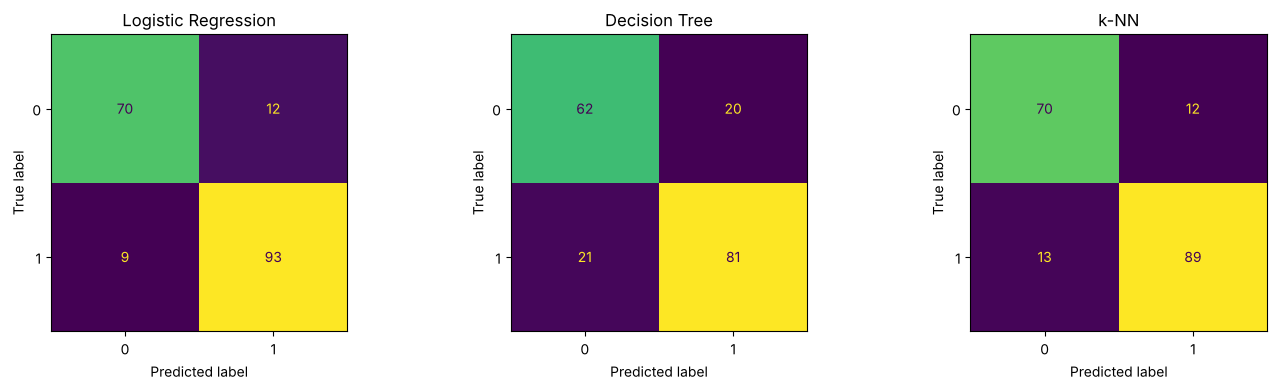

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.886,0.886,0.912,0.899,0.933
Decision Tree,0.777,0.802,0.794,0.798,0.775
k-NN,0.864,0.881,0.873,0.877,0.927


In [ ]:
models = {
    "Logistic Regression": Pipeline([("pre", make_pre()), ("clf", LogisticRegression(max_iter=2000))]),
    "Decision Tree":       Pipeline([("pre", make_pre()), ("clf", DecisionTreeClassifier(random_state=42))]),
    "k-NN":                Pipeline([("pre", make_pre()), ("clf", KNeighborsClassifier())]),
}
rows = {}
fig,  axes= plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, m) in zip(axes, models.items()):
    m.fit(X_train, y_train)
    pred = m.predict(X_test); proba = m.predict_proba(X_test)[:, 1]
    rows[name] = {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                  "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                  "ROC-AUC": roc_auc_score(y_test, proba)}
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(ax=ax, colorbar=False)
    ax.set_title(name); print(name, "confusion matrix:\n", confusion_matrix(y_test, pred), "\n")
plt.tight_layout(); plt.show()
t1 = pd.DataFrame(rows).T.round(3); display(t1)

**Interpretation.**
- **Precision** = TP / (TP + FP): of the patients predicted ill, how many really are. **Recall** = TP / (TP + FN): of the really ill patients, how many are found. **F1** is their harmonic mean, so it is high only when both are high.
- Logistic Regression is best on every metric (F1 = 0.899, ROC-AUC = 0.933); k-NN is close behind; the Decision Tree is clearly the weakest (F1 = 0.798, 20 + 21 errors).
- **Chosen metric: recall (with F1 as a balance check).** A false negative means a sick patient is sent home, which is much more costly than a false positive (an extra examination). Logistic Regression also has the best recall (0.912, 9 missed patients). F1 is used as the selection metric in the later tasks because it does not allow high recall to be reached by predicting "ill" for everyone.

## Task 2. Overfitting and underfitting

,max_depth,train_acc,test_acc,gap
0,1,0.827,0.761,0.066
1,2,0.827,0.761,0.066
2,3,0.857,0.832,0.025
3,5,0.891,0.788,0.103
4,10,0.990,0.799,0.192
5,None,1.000,0.777,0.223


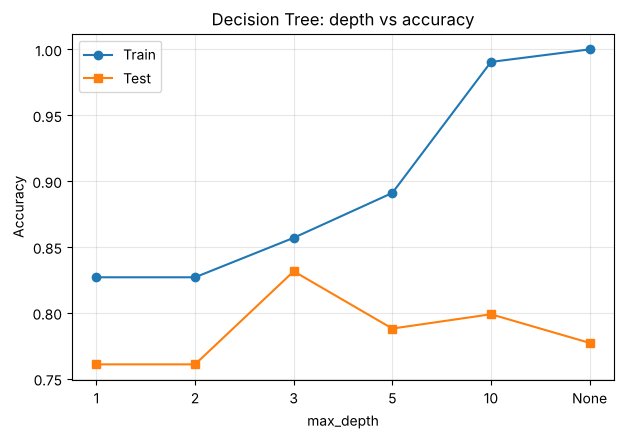

In [4]:
pre = make_pre().fit(X_train)            # preprocessing fitted on training data only
Xtr, Xte = pre.transform(X_train), pre.transform(X_test)
res = []
for d in [1, 2, 3, 5, 10, None]:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(Xtr, y_train)
    res.append({"max_depth": str(d), "train_acc": t.score(Xtr, y_train), "test_acc": t.score(Xte, y_test)})
t2 = pd.DataFrame(res); t2["gap"] = t2.train_acc - t2.test_acc; display(t2.round(3))
plt.figure(figsize=(7, 4.5))
plt.plot(t2.max_depth, t2.train_acc, "o-", label="Train"); plt.plot(t2.max_depth, t2.test_acc, "s-", label="Test")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.title("Decision Tree: depth vs accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Interpretation.**
- **Underfitting:** `max_depth` = 1 and 2 give identical, low accuracy (train 0.827 / test 0.761): the tree is too simple, both scores are low.
- **Best generalization:** `max_depth` = 3 (test 0.832, gap 0.025).
- **Overfitting:** depth 10 and `None` have train accuracy 0.99-1.00 but test accuracy only 0.78-0.80; the train-test gap grows to 0.19-0.22, i.e. the tree memorizes the training data (including noise).
- Limiting depth restricts the number of splits, so leaves must cover many samples and the model can capture only the main patterns. This lowers variance, shrinks the train-test gap and usually improves performance on new data.

## Task 3. Stratified 5-fold cross-validation (F1)

In [5]:
rows = {}
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1")
    rows[name] = {**{f"Fold {i+1}": v for i, v in enumerate(s)}, "Mean F1": s.mean(), "Std": s.std()}
t3 = pd.DataFrame(rows).T.round(3); display(t3)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean F1,Std
Logistic Regression,0.852,0.828,0.866,0.894,0.877,0.863,0.023
Decision Tree,0.810,0.725,0.848,0.874,0.778,0.807,0.052
k-NN,0.869,0.814,0.883,0.883,0.880,0.866,0.026


**Interpretation.**
- k-NN (mean F1 0.866) and Logistic Regression (0.863) perform almost equally; the Decision Tree is clearly worse (0.807).
- Stability: Logistic Regression has the smallest std (0.023), k-NN 0.026, while the tree is the least stable (std 0.052; fold F1 ranges from 0.725 to 0.874), which again reflects the high variance of an unpruned tree.
- **Why cross-validation:** a single train/test split gives one noisy estimate that depends on which rows landed in the test set. With k-fold every observation is used for validation once, and the mean ± std gives both the expected performance and its variability, so models can be compared more reliably.

## Task 4. Hyperparameter optimization (Decision Tree): GridSearchCV vs RandomizedSearchCV

In [6]:
base = Pipeline([("pre", make_pre()), ("clf", DecisionTreeClassifier(random_state=42))])
grid = {"clf__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
        "clf__min_samples_split": [2, 5, 10, 20],
        "clf__min_samples_leaf": [1, 2, 4, 8]}
gs = GridSearchCV(base, grid, scoring="f1", cv=cv, n_jobs=-1)
t0 = time.time(); gs.fit(X_train, y_train); t_grid = time.time() - t0

dist = {"clf__max_depth": randint(2, 15), "clf__min_samples_split": randint(2, 40),
        "clf__min_samples_leaf": randint(1, 20)}
rs = RandomizedSearchCV(base, dist, n_iter=30, scoring="f1", cv=cv, n_jobs=-1, random_state=42)
t0 = time.time(); rs.fit(X_train, y_train); t_rand = time.time() - t0

summary = pd.DataFrame({
    "Configurations": [len(gs.cv_results_["params"]), len(rs.cv_results_["params"])],
    "Model fits (x5 folds)": [len(gs.cv_results_["params"])*5, len(rs.cv_results_["params"])*5],
    "Search time, s": [round(t_grid, 2), round(t_rand, 2)],
    "Best CV F1": [round(gs.best_score_, 4), round(rs.best_score_, 4)],
    "Best params": [gs.best_params_, rs.best_params_]}, index=["GridSearchCV", "RandomizedSearchCV"])
pd.set_option("display.max_colwidth", None); display(summary)

default = base.fit(X_train, y_train)
final = {}
for name, m in [("Default tree", default), ("Grid best", gs.best_estimator_), ("Random best", rs.best_estimator_)]:
    p = m.predict(X_test)
    final[name] = {"Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
                   "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p),
                   "ROC-AUC": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])}
t4 = pd.DataFrame(final).T.round(3); display(t4)

,Configurations,Model fits (x5 folds),"Search time, s",Best CV F1,Best params
GridSearchCV,128,640,7.27,0.8548,"{'clf__max_depth': 4, 'clf__min_samples_leaf': 8, 'clf__min_samples_split': 2}"
RandomizedSearchCV,30,150,1.58,0.8632,"{'clf__max_depth': 4, 'clf__min_samples_leaf': 12, 'clf__min_samples_split': 4}"


,Accuracy,Precision,Recall,F1,ROC-AUC
Default tree,0.777,0.802,0.794,0.798,0.775
Grid best,0.793,0.820,0.804,0.812,0.848
Random best,0.793,0.820,0.804,0.812,0.848


**Interpretation.**
- **Search space:** Grid = 8 × 4 × 4 = 128 fixed combinations (640 fits); Randomized = 30 combinations sampled from integer ranges (150 fits), i.e. it can try values that are not on the grid.
- **Cost:** Randomized search was about 4-5× faster (≈1.6 s vs ≈7.6 s), and the cost grows multiplicatively with each extra hyperparameter for the grid but stays fixed (`n_iter`) for the random search.
- **Result:** both found shallow trees (`max_depth` = 4) with larger leaves. Randomized search even reached a slightly higher CV F1 (0.863 vs 0.855) because it tried `min_samples_leaf` = 12, which is not in the grid. The two selected models have the same test metrics.
- **Test vs default:** tuned tree F1 0.812 vs 0.798, ROC-AUC 0.848 vs 0.775: a modest gain in F1 and a clear gain in ROC-AUC, as regularization reduces overfitting. The tuned tree is still below Logistic Regression from Task 1.
- **Why not tune on the test set:** if the test set is used to choose hyperparameters, it stops being unseen data; the reported score becomes optimistically biased because the model was selected to fit exactly this sample. Hyperparameters must be chosen by cross-validation on the training data, and the test set used once at the end.

# Part II. ANOVA and statistical feature selection

## Task 5. One-way ANOVA: MaxHR across ChestPainType (4 independent groups)

               count    mean    std  median
ChestPainType                              
ASY              496  128.48  23.48   128.0
ATA              173  150.21  22.28   152.0
NAP              203  143.24  25.61   147.0
TA                46  147.89  23.13   145.0

F-statistic = 47.053, p-value = 2.787e-28


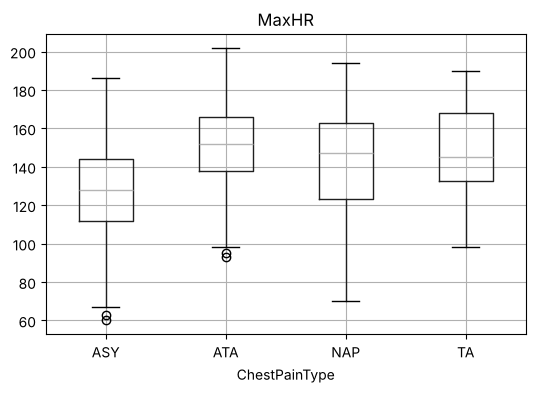

In [7]:
numerical_column, group_column = "MaxHR", "ChestPainType"
print(df.groupby(group_column)[numerical_column].agg(["count", "mean", "std", "median"]).round(2))
groups = [g[numerical_column].values for _, g in df.groupby(group_column)]
F, p = f_oneway(*groups)
print(f"\nF-statistic = {F:.3f}, p-value = {p:.3e}")
df.boxplot(column=numerical_column, by=group_column, figsize=(6, 4)); plt.suptitle(""); plt.show()

**Hypotheses.** H0: mean MaxHR is the same in all four chest-pain groups (μ_ASY = μ_ATA = μ_NAP = μ_TA). H1: at least one group mean differs.

**Result.** F = 47.05, p ≈ 2.8·10⁻²⁸ < 0.05, so H0 is rejected: mean MaxHR differs significantly between chest-pain types (ASY has the lowest mean, ≈128 bpm; ATA the highest, ≈150 bpm).

**Caveat.** ANOVA only shows that **at least one** mean differs; it does not show that all means differ (for example, ATA, NAP and TA are close to each other) and does not say which pairs differ. A post-hoc test would be needed for that.

## Task 7. ANOVA F-test for feature ranking

,Feature,F_statistic,p_value
0,MaxHR,145.522825,1.084541e-30
1,Oldpeak,120.977606,3.784657e-26
2,FastingBS,53.682093,6.240608e-13
3,Age,46.618076,1.812908e-11
4,RestingBP,7.704128,5.650109e-03
5,Cholesterol,2.197340,1.386795e-01


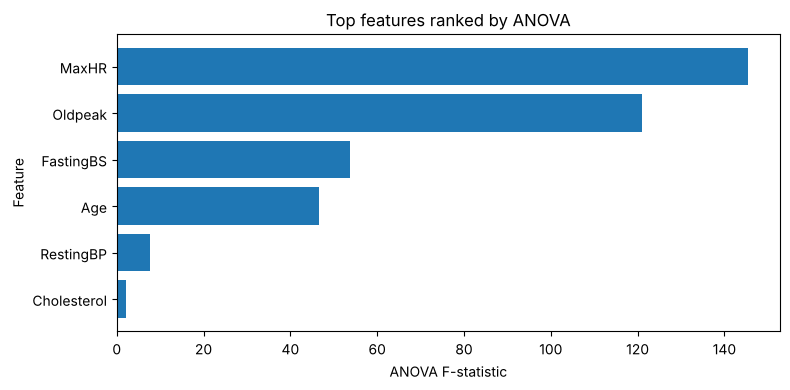

Features with p < 0.05: ['MaxHR', 'Oldpeak', 'FastingBS', 'Age', 'RestingBP']


In [8]:
# numeric features only; imputer fitted on the training part only
imp = SimpleImputer(strategy="median").fit(X_train[num_cols])
X_train_num = pd.DataFrame(imp.transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
F_values, p_values = f_classif(X_train_num, y_train)
anova_results = pd.DataFrame({"Feature": num_cols, "F_statistic": F_values, "p_value": p_values}
                            ).sort_values("F_statistic", ascending=False).reset_index(drop=True)
display(anova_results)
top = anova_results.head(10).sort_values("F_statistic")
plt.figure(figsize=(8, 4)); plt.barh(top["Feature"], top["F_statistic"])
plt.xlabel("ANOVA F-statistic"); plt.ylabel("Feature"); plt.title("Top features ranked by ANOVA"); plt.tight_layout(); plt.show()
print("Features with p < 0.05:", anova_results.loc[anova_results.p_value < 0.05, "Feature"].tolist())

**Interpretation.**
- Ranking by F-statistic: `MaxHR` (145.5), `Oldpeak` (121.0), `FastingBS` (53.7), `Age` (46.6), `RestingBP` (7.7), `Cholesterol` (2.2). Only 6 numerical features exist, so the chart shows all of them.
- Features with p < 0.05: MaxHR, Oldpeak, FastingBS, Age, RestingBP. `Cholesterol` (p = 0.139) is not significantly related to the target, partly because 172 of its values were missing and imputed.
- **A high F-statistic does not guarantee better predictive performance:** the F-test looks at each feature separately and only at differences in class means, so it ignores correlation and redundancy between features (two highly ranked but correlated features add little together), interactions and non-linear relations, and a significant difference can still be too small to separate classes. Statistical significance is not the same as predictive usefulness.

## Task 8. ANOVA-based feature selection and model optimization

In [9]:
Xtr_n, Xte_n = X_train[num_cols], X_test[num_cols]
p_all = Pipeline([("imp", SimpleImputer(strategy="median")), ("scaler", StandardScaler()),
                  ("classifier", LogisticRegression(max_iter=2000))])
p_sel = Pipeline([("imp", SimpleImputer(strategy="median")), ("select", SelectKBest(f_classif, k=3)),
                  ("scaler", StandardScaler()), ("classifier", LogisticRegression(max_iter=2000))])
cv_all = cross_val_score(p_all, Xtr_n, y_train, cv=cv, scoring="f1")
cv_sel = cross_val_score(p_sel, Xtr_n, y_train, cv=cv, scoring="f1")
print(f"All {len(num_cols)} features : mean F1 = {cv_all.mean():.4f} +/- {cv_all.std():.4f}")
print(f"SelectKBest k=3  : mean F1 = {cv_sel.mean():.4f} +/- {cv_sel.std():.4f}")

# only 6 numerical features -> k limited to 2..6
param_grid = {"select__k": [2, 3, 4, 5, 6], "classifier__C": [0.01, 0.1, 1, 10, 100]}
search = GridSearchCV(p_sel, param_grid, scoring="f1", cv=cv, n_jobs=-1).fit(Xtr_n, y_train)
print("Best params:", search.best_params_, "| best CV F1:", round(search.best_score_, 4))
sel_mask = search.best_estimator_.named_steps["select"].get_support()
print("Selected features:", [c for c, s in zip(num_cols, sel_mask) if s])

res = {}
for name, m in [("All features (no selection)", p_all.fit(Xtr_n, y_train)), ("SelectKBest + GridSearch", search.best_estimator_)]:
    p = m.predict(Xte_n)
    res[name] = {"Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p),
                 "ROC-AUC": roc_auc_score(y_test, m.predict_proba(Xte_n)[:, 1])}
t8 = pd.DataFrame(res).T.round(3); display(t8)

All 6 features : mean F1 = 0.7803 +/- 0.0441
SelectKBest k=3  : mean F1 = 0.7752 +/- 0.0484


Best params: {'classifier__C': 0.01, 'select__k': 6} | best CV F1: 0.7872
Selected features: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']


,Accuracy,Precision,Recall,F1,ROC-AUC
All features (no selection),0.772,0.783,0.814,0.798,0.869
SelectKBest + GridSearch,0.783,0.777,0.853,0.813,0.876


**Interpretation.**
- Cross-validation (training set, F1): all 6 numeric features 0.780 ± 0.044; fixed `SelectKBest(k=3)` 0.775 ± 0.048, so dropping features did not help.
- GridSearchCV chose `k = 6` (all features) and `C = 0.01` (strong regularization); best CV F1 = 0.787.
- Test set: tuned pipeline F1 0.813, recall 0.853, ROC-AUC 0.876 vs all-features model F1 0.798, recall 0.814, ROC-AUC 0.869.
- **Conclusion:** feature selection itself was **not** beneficial: the search kept every feature, since with only 6 features there is little redundancy to remove. The small improvement comes from tuning `C` (regularization), and the difference (+0.015 F1 on 184 test samples) is within normal noise. Note also that these models use only numeric features, so they are weaker than the Task 1 models that also use categorical features (e.g. `ST_Slope`, `ExerciseAngina`).